# Build an analytical dashboard

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/19-dashboard.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/19-dashboard.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `56495ca8d569ac21c3f9e8c45868f159bb2a2eeaf1668b9fa98e784c74399475`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Build an analytical dashboard

**Lesson 19 · Original synthetic data · Independent educational project**

## Objectives

Coordinate a map, time series and distribution; retain units and provenance.

[Previous](18-time.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/19-dashboard.ipynb) · [Next](20-performance.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=19-dashboard.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

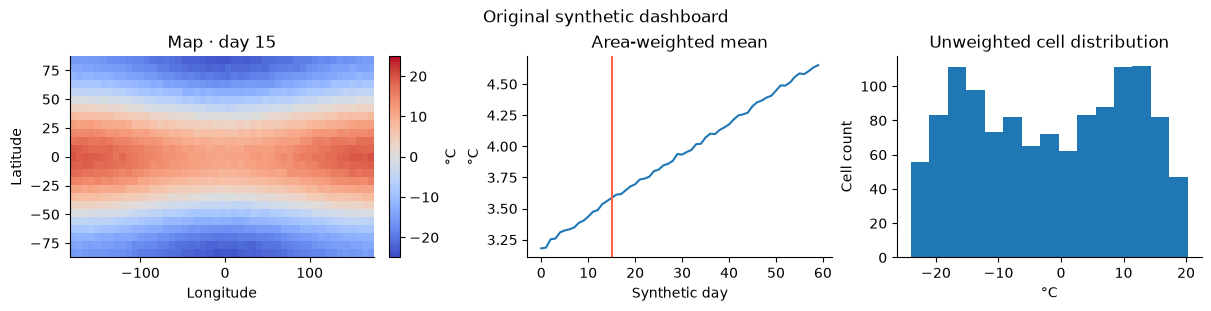

In [2]:
cube = lab.synthetic_cube(); day = 15
field = cube["temperature"][day]-273.15
series = lab.global_mean(cube["temperature"], cube["lat"])-273.15
fig, axes = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
im = axes[0].pcolormesh(cube["lon"], cube["lat"], field, shading="auto", cmap="coolwarm", vmin=-25, vmax=25)
axes[0].set(title=f"Map · day {day}", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(im, ax=axes[0], label="°C")
axes[1].plot(series); axes[1].axvline(day, color="tomato")
axes[1].set(title="Area-weighted mean", xlabel="Synthetic day", ylabel="°C")
counts, edges, _ = axes[2].hist(field.ravel(), bins=15)
axes[2].set(title="Unweighted cell distribution", xlabel="°C", ylabel="Cell count")
fig.suptitle("Original synthetic dashboard")
plt.show()
assert counts.sum() == field.size

## Exercise

Change the selected day in all panels together. Explain why the cell histogram and area-weighted mean use different weighting conventions.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interactive Lab experiment

Move the time slider, change the variable or rotate the 3D view. This widget runs in a Python kernel in Lab; the published book preserves a static output. Explain which control changes the data and which only changes its display.

In [ ]:
import ipywidgets as widgets
from IPython.display import display
interactive_cube = lab.synthetic_cube(nlat=19, nlon=31)
def explore(day=0, variable="temperature", azimuth=-55):
    units = interactive_cube["units"][variable]
    field = interactive_cube[variable][day]
    bounds = (245, 300) if variable == "temperature" else (0, 8)
    fig = plt.figure(figsize=(8, 4))
    ax = fig.add_subplot(121)
    im = ax.pcolormesh(interactive_cube["lon"], interactive_cube["lat"], field, shading="auto", vmin=bounds[0], vmax=bounds[1])
    ax.set(xlabel="Longitude", ylabel="Latitude")
    fig.colorbar(im, ax=ax, label=units)
    other = fig.add_subplot(122)
    other.plot(lab.global_mean(interactive_cube[variable], interactive_cube["lat"]))
    other.axvline(day, color="tomato"); other.set(xlabel="Synthetic day", ylabel=units)
    fig.suptitle(f"Synthetic {variable}, day {day}")
    plt.tight_layout(); plt.show()
controls = widgets.interactive(explore, day=widgets.IntSlider(min=0,max=59,value=0),
                               variable=["temperature", "precipitation"], azimuth=widgets.fixed(-55))
display(controls)

## Interpretation and limits

A dashboard is meaningful when panels share a clear selection state. The gallery implements live variable, time and rendering controls for related synthetic views.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://matplotlib.org/stable/users/explain/axes/arranging_axes.html) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).